# ¿Cuánto ingreso se pierde por cancelaciones y qué reservas hay que vigilar?
**Análisis exploratorio — Hotel Booking Demand (Portugal) · ~118.500 reservas reales, jul-2015 a ago-2017**

**Pregunta de negocio:** más de un tercio de las reservas se cancela. Quiero medir cuánto ingreso representa,
qué características tienen las reservas que se caen y si se pueden identificar **al momento de reservar**,
para que el hotel actúe antes (depósito, reconfirmación, sobreventa controlada).

Datos: *Hotel Booking Demand* (Kaggle; Antonio, Almeida y Nunes, 2019). Tabla limpia generada por `src/clean.py`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path

FIG = Path('../reports/figures'); FIG.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, GRAY = '#2a78d6', '#eb6834', '#b7b6b0'
INK, INK2 = '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.figsize': (10, 4.2), 'figure.dpi': 110, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.spines.left': False, 'axes.edgecolor': GRAY,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': '#e6e5e1', 'grid.linewidth': 0.8,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK,
    'font.size': 10, 'legend.frameon': False,
})
pct = mtick.PercentFormatter(1, 0)
def save(name):
    plt.tight_layout(); plt.savefig(FIG / f'{name}.png', bbox_inches='tight', facecolor='white'); plt.show()

b = pd.read_csv('../data/processed/bookings.csv', parse_dates=['arrival_date'])
canc = b.is_canceled == 1
print(f'Reservas: {len(b):,} | tasa de cancelación: {canc.mean():.1%}')
print(f'Ingreso realizado: € {b.loc[~canc, "revenue"].sum()/1e6:.1f} M | ingreso de reservas canceladas: € {b.loc[canc, "revenue"].sum()/1e6:.1f} M')
print(b.groupby('hotel').is_canceled.mean().map('{:.1%}'.format))

Reservas: 118,563 | tasa de cancelación: 37.3%
Ingreso realizado: € 26.0 M | ingreso de reservas canceladas: € 16.7 M
hotel
Hotel urbano    41.9%
Resort          28.0%
Name: is_canceled, dtype: str


**Lectura:** el 37% de las reservas se cancela, y esas reservas representaban € 16,7 M, el equivalente al
**64% de lo que efectivamente se facturó**. Parte de esas habitaciones se revende, por eso hablo de
*ingreso en riesgo* y no de pérdida neta. El hotel urbano cancela mucho más que el resort (42% vs 28%).

## 1. Anticipación: el factor más fuerte

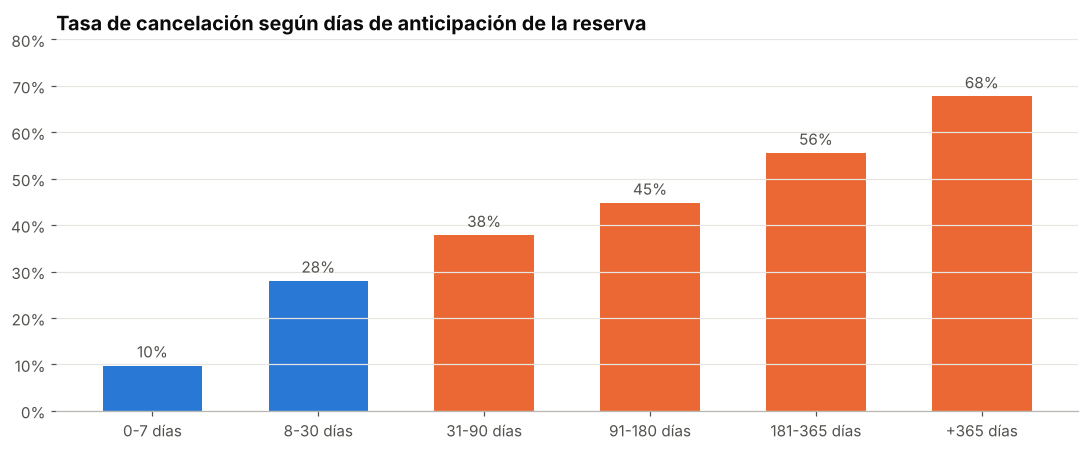

In [2]:
order = ['0-7 días', '8-30 días', '31-90 días', '91-180 días', '181-365 días', '+365 días']
lt = b.groupby('lead_time_band').is_canceled.mean().reindex(order)
fig, ax = plt.subplots()
bars = ax.bar(lt.index, lt.values, color=[BLUE, BLUE, ORANGE, ORANGE, ORANGE, ORANGE], width=0.6)
ax.bar_label(bars, labels=[f'{v:.0%}' for v in lt.values], color=INK2, padding=3)
ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, 0.8)
ax.set_title('Tasa de cancelación según días de anticipación de la reserva')
save('01_cancelacion_por_anticipacion')

**Lectura:** cuanto antes se reserva, más se cancela. Con menos de una semana de anticipación cancela 1 de cada 10;
con más de 6 meses, más de la mitad. Las reservas de largo plazo son las que necesitan una política distinta.

## 2. ¿Por qué canal entran las reservas que se caen?

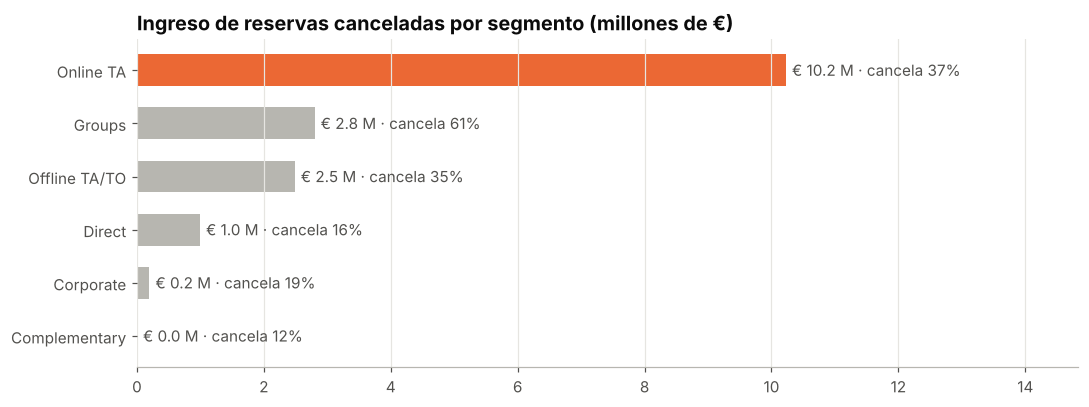

Agencias online (Booking, Expedia, etc.): 61% del ingreso cancelado


In [3]:
seg = b.groupby('market_segment').agg(reservas=('is_canceled', 'size'), tasa=('is_canceled', 'mean'),
        cancelado=('revenue', lambda s: s[canc.loc[s.index]].sum() / 1e6))
seg = seg[seg.reservas >= 500].sort_values('cancelado')
fig, ax = plt.subplots(figsize=(10, 3.8))
bars = ax.barh(seg.index, seg.cancelado, color=[ORANGE if s == 'Online TA' else GRAY for s in seg.index], height=0.6)
ax.bar_label(bars, labels=[f'€ {v:.1f} M · cancela {t:.0%}' for v, t in zip(seg.cancelado, seg.tasa)], color=INK2, padding=4)
ax.set_xlim(0, seg.cancelado.max() * 1.45); ax.grid(axis='x'); ax.grid(axis='y', visible=False)
ax.set_title('Ingreso de reservas canceladas por segmento (millones de €)')
save('02_ingreso_cancelado_por_segmento')
share = seg.loc['Online TA', 'cancelado'] / seg.cancelado.sum()
print(f'Agencias online (Booking, Expedia, etc.): {share:.0%} del ingreso cancelado')

**Lectura:** las **agencias online** concentran el 61% del ingreso cancelado: muchas ofrecen cancelación
gratuita y el cliente reserva "por las dudas". Los grupos cancelan más (61%), pero mueven menos dinero.
La venta directa cancela la mitad que las agencias (15%), lo que la vuelve el canal más confiable.

## 3. Señales de compromiso del huésped

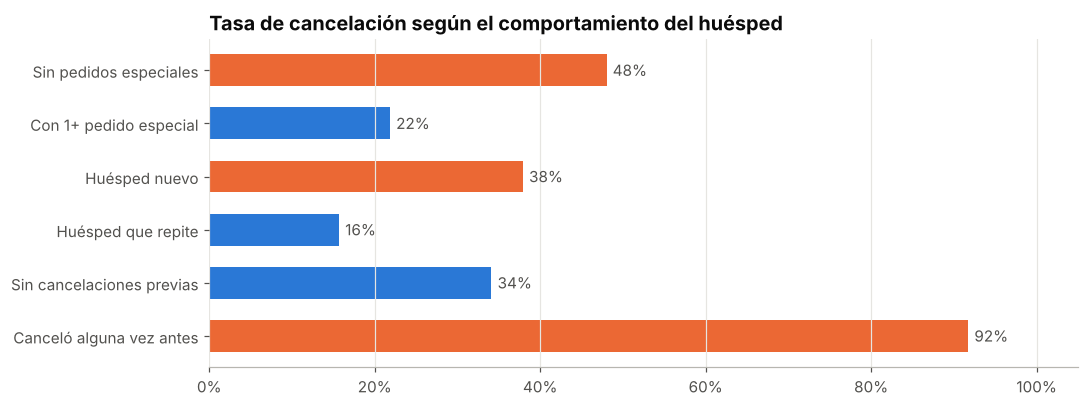

In [4]:
rows = {
    'Sin pedidos especiales': b.loc[b.total_of_special_requests == 0, 'is_canceled'].mean(),
    'Con 1+ pedido especial': b.loc[b.total_of_special_requests > 0, 'is_canceled'].mean(),
    'Huésped nuevo': b.loc[b.is_repeated_guest == 0, 'is_canceled'].mean(),
    'Huésped que repite': b.loc[b.is_repeated_guest == 1, 'is_canceled'].mean(),
    'Sin cancelaciones previas': b.loc[~b.had_previous_cancel, 'is_canceled'].mean(),
    'Canceló alguna vez antes': b.loc[b.had_previous_cancel, 'is_canceled'].mean(),
}
s = pd.Series(rows)[::-1]
fig, ax = plt.subplots(figsize=(10, 3.8))
bars = ax.barh(s.index, s.values, color=[ORANGE if k in ('Sin pedidos especiales', 'Huésped nuevo', 'Canceló alguna vez antes') else BLUE for k in s.index], height=0.6)
ax.bar_label(bars, labels=[f'{v:.0%}' for v in s.values], color=INK2, padding=4)
ax.xaxis.set_major_formatter(pct); ax.set_xlim(0, 1.05); ax.grid(axis='x'); ax.grid(axis='y', visible=False)
ax.set_title('Tasa de cancelación según el comportamiento del huésped')
save('03_senales_de_compromiso')

**Lectura:** el huésped que pide algo (cuna, piso alto, cama extra) ya está "comprometido": cancela 22% contra 48%.
Quien ya canceló antes vuelve a cancelar el 92% de las veces. Son señales que el hotel conoce el día que se hace la reserva.

## 4. Estacionalidad

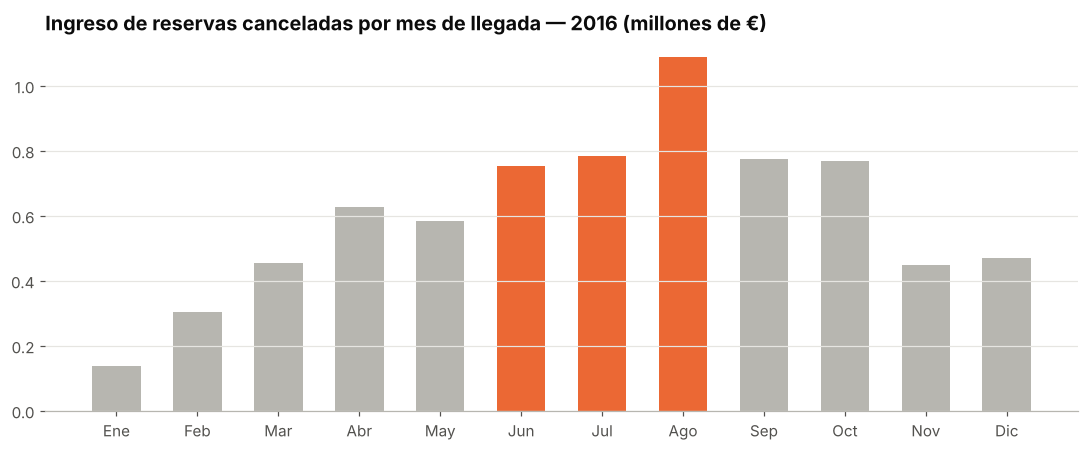

Jun-ago concentran el 36% del ingreso cancelado


In [5]:
# Solo 2016: es el único año completo (jul-ago aparecen en 3 años y el resto en 2; mezclarlos infla el verano)
y16 = b[b.arrival_date_year == 2016]
mes = y16.groupby(['arrival_month_num', 'arrival_month_name']).agg(
    cancelado=('revenue', lambda s: s[canc.loc[s.index]].sum() / 1e6)).reset_index()
fig, ax = plt.subplots()
bars = ax.bar(mes.arrival_month_name, mes.cancelado,
              color=[ORANGE if m in (6, 7, 8) else GRAY for m in mes.arrival_month_num], width=0.6)
ax.set_title('Ingreso de reservas canceladas por mes de llegada — 2016 (millones de €)')
save('04_estacionalidad')
ver = mes[mes.arrival_month_num.isin([6, 7, 8])].cancelado.sum() / mes.cancelado.sum()
print(f'Jun-ago concentran el {ver:.0%} del ingreso cancelado')

**Lectura:** en 2016, el verano europeo (junio-agosto) concentró el 36% del ingreso cancelado en solo un cuarto del año: es justo cuando una habitación
vacía cuesta más. Son los meses donde una política de depósito o sobreventa controlada rinde más.

## 5. ¿Se puede anticipar? Nivel de riesgo al momento de reservar

Armé un **puntaje simple de riesgo** (0 a 7) usando **solo información disponible el día de la reserva**:

| Señal | Puntos |
|---|---|
| Anticipación 31-90 días / más de 90 días | 1 / 2 |
| Entra por agencia (online u offline) o grupo | 1 |
| Sin pedidos especiales | 1 |
| Canceló alguna vez antes | 2 |
| Huésped nuevo | 1 |

Niveles: **Bajo** (0-2), **Medio** (3-4), **Alto** (5+). Las reglas se definieron mirando 2015-2016 y se
**validan sobre las llegadas de 2017**, que no se usaron para diseñarlas.

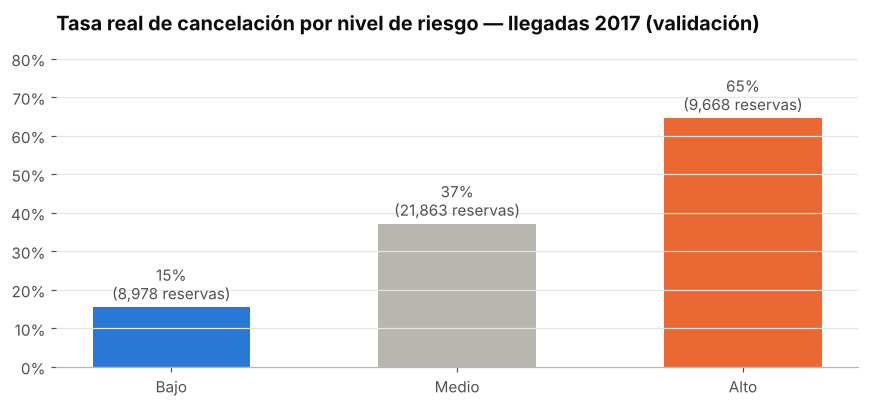

Riesgo alto cancela 4.2x más que riesgo bajo


In [6]:
t17 = b[b.arrival_date_year == 2017]
val = t17.groupby('risk_level').is_canceled.agg(['mean', 'size']).reindex(['Bajo', 'Medio', 'Alto'])
fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(val.index, val['mean'], color=[BLUE, GRAY, ORANGE], width=0.55)
ax.bar_label(bars, labels=[f'{m:.0%}\n({n:,} reservas)' for m, n in zip(val['mean'], val['size'])], color=INK2, padding=3)
ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, 0.85)
ax.set_title('Tasa real de cancelación por nivel de riesgo — llegadas 2017 (validación)')
save('05_validacion_riesgo_2017')
print(f"Riesgo alto cancela {val.loc['Alto','mean']/val.loc['Bajo','mean']:.1f}x más que riesgo bajo")

**Lectura:** el puntaje separa bien sobre datos nuevos: una reserva de riesgo alto se cancela el 65% de las veces;
una de riesgo bajo, el 15% (4,2 veces menos). Con reglas tan simples, recepción o revenue management pueden
aplicarlo sin un modelo complejo.

## 6. Impacto estimado

In [7]:
# Escenario sobre un año completo (2016): una política para reservas de riesgo ALTO
# (depósito parcial o reconfirmación 30 días antes) baja su cancelación 10 puntos porcentuales.
y16 = b[b.arrival_date_year == 2016]
alto = y16[y16.risk_level == 'Alto']
recuperable = len(alto) * 0.10 * alto.revenue.mean()
print(f"Reservas de riesgo alto en 2016: {len(alto):,} | tasa de cancelación: {alto.is_canceled.mean():.0%}")
print(f"Ingreso recuperable por cada 10 pp menos de cancelación: € {recuperable/1e3:,.0f} mil por año")

Reservas de riesgo alto en 2016: 15,226 | tasa de cancelación: 66%
Ingreso recuperable por cada 10 pp menos de cancelación: € 502 mil por año


## Conclusiones y recomendaciones

| # | Hallazgo | Recomendación |
|---|----------|---------------|
| 1 | 37% de cancelación; € 16,7 M en reservas caídas (64% de lo facturado) | Seguir la tasa de cancelación y el ingreso en riesgo como KPI mensual |
| 2 | Reservas con +90 días de anticipación cancelan 45-68% | Depósito parcial o reconfirmación obligatoria para estadías lejanas |
| 3 | Las agencias online concentran el 61% del ingreso cancelado; la venta directa cancela 15% | Incentivar la reserva directa (mejor tarifa o beneficio) |
| 4 | Sin pedidos especiales cancela 2,2x; quien canceló antes, 92% | Usar estas señales en el puntaje de riesgo |
| 5 | Puntaje simple validado en 2017: riesgo alto 65% vs bajo 15% | Sobreventa controlada solo sobre reservas de riesgo alto, en jun-ago |

**Limitaciones:** los datos son de dos hoteles de Portugal; el ingreso cancelado es bruto (parte se revende);
las reservas con depósito no reembolsable muestran una tasa de cancelación del 99%, probablemente un error de registro,
por eso no se usa esa variable para concluir (ver `reports/calidad_de_datos.md`).